# 03 — Land and Sea-Ice Initial Conditions for RTENSO2026: Model Climatology with Observed Anomalies

This notebook introduces a third initialization strategy, `clim_anom`, to complement the existing `clim` and `obs` year-selection methods implemented in `02_build_climatology_ic.ipynb` (which remains unchanged).

Rather than using a selected historical restart without modification, this approach combines a representative model climatological state with observed anomalies for the target initialization date. The goal is to incorporate observed land and sea-ice conditions while retaining the physical consistency of a spun-up E3SM restart.

## 1. Climatological Baseline

The method first selects the `clim` restart year identified by `02_build_climatology_ic.ipynb`, using the same candidate years, spatial aggregation, and selection criteria.

This restart represents the BruteForce simulation state closest to the candidate-year climatology. It serves as the baseline for all restart variables, including those that cannot be directly constrained by observations. This preserves a physically spun-up, internally consistent model state before the observed-anomaly adjustments are applied.

## 2. Incorporating Observed Anomalies

For each observable key field, the target model state is constructed by adding an observed anomaly to the model climatology:

$$
t_i = \bar{x}_i + a_i,
$$

where

$$
a_i =
\operatorname{clip}\left(
\frac{o_{T,i}-\bar{o}_i}{\sigma_i^o},
-z_{\max},z_{\max}
\right)\sigma_i.
$$

Here:

- \(\bar{x}_i\) and \(\sigma_i\) are the model climatological mean and interannual standard deviation at grid point \(i\).
- \(o_{T,i}\) is the observed value on the target initialization date.
- \(\bar{o}_i\) and \(\sigma_i^o\) are the observed climatological mean and interannual standard deviation over the corresponding candidate years.
- \(z_{\max}\) limits the magnitude of standardized anomalies to reduce sensitivity to observational artifacts and extreme outliers.

Observational constraints are obtained from **ERA5-Land for terrestrial variables** and **NOAA/NSIDC Climate Data Record (CDR) for sea-ice concentration**.

By transferring standardized anomalies rather than raw differences, the method accounts for systematic differences in climatology and variability between the model and observations.

Two scaling options are supported:

- **`SCALE = "point"` (default):** Standardizes anomalies locally at each grid cell, allowing the model's local variability to determine the anomaly magnitude.
- **`SCALE = "field"`:** Applies a single field-wide variability ratio, \(S_{\mathrm{model}}/S_{\mathrm{obs}}\), to scale observed anomalies.

The anomaly clipping threshold \(z_{\max}\) also helps prevent unrealistic adjustments caused by observational artifacts, such as ERA5/ERA5-Land snow-depth (`sd`) values reaching the 10 m cap over high mountains and along the Antarctic coast.

## 3. Applying Consistent Restart Adjustments

The target anomalies are applied to the selected climatological restart through either multiplicative scaling (`

In [1]:
from pathlib import Path
import importlib
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.path as mpath

SEARCH_ROOTS = (Path.cwd().resolve(), *Path.cwd().resolve().parents)
HELPER_RELATIVE_PATHS = (
    Path("util"),
    Path("rtenso2026/util"),
    Path("ensemble_init/rtenso2026/util"),
    Path("e3sm_s2d_proc/ensemble_init/rtenso2026/util"),
)
HELPER_DIR = next(
    (
        root / relative_path
        for root in SEARCH_ROOTS
        for relative_path in HELPER_RELATIVE_PATHS
        if (root / relative_path / "anom_restart.py").is_file()
    ),
    None,
)
if HELPER_DIR is None:
    raise FileNotFoundError("Could not find util/anom_restart.py from the notebook directory.")
if str(HELPER_DIR) not in sys.path:
    sys.path.insert(0, str(HELPER_DIR))

import clim_restart
import anom_restart
clim_restart = importlib.reload(clim_restart)
anom_restart = importlib.reload(anom_restart)
from clim_restart import (
    compute_distances,
    era5_available,
    load_key_fields,
    make_plan,
    read_key_fields,
    select_years,
)
from anom_restart import (
    AnomalySettings,
    compute_increments,
    read_states,
    state_distance,
    write_anomaly_restarts,
)

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)

## Configuration

Candidate years, box, and mode match `02`, so the base year is the `clim` year written there.

In [2]:
# Model initial-condition archive (BruteForce restarts, opened read-only).
SRC_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/v3.LR.S2D.ENSINT/BruteForce")
SRC_PREFIX = "20251024_s2d_spinup"

# Observations for the anomaly: ERA5-Land (land) + NOAA/NSIDC CDR (sea ice), the default
# obs_era5land_nsidc branch of 02.
OBS_DATA = Path("/global/cfs/cdirs/e3sm/zhan391/data")
OBS_ROOT = {"elm": OBS_DATA / "ERA5_LND", "mpassi": OBS_DATA / "NOAA_NSIDC"}
OBS_FIELDS = {"elm": ["sd", "swvl1", "swvl2-4", "stl1", "stl2-4"], "mpassi": ["ci"]}
OBS_NAME = "ERA5-Land/NSIDC"     # label in tables and figures

# Fixed RTENSO2026 output location: OUT_ROOT/YYYYMMDD/<LABEL>/<prefix>.<stream>.<date>.nc
OUT_ROOT = Path("/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions")
OUT_PREFIX = "20251024_s2d_spinup"   # matches my_refcase2 in the hindcast driver
LABEL = "clim_anom"                  # new subdirectory; clim/ and obs*/ are not touched

COMPONENTS = ["elm", "mosart", "mpassi"]

TEST_DATES = ["2015-02-01", "2015-05-01", "2015-08-01", "2015-11-01"]
HINDCAST_DATES = ["2026-02-01", "2026-05-01", "2026-08-01", "2026-11-01"]
TARGET_DATES = TEST_DATES + HINDCAST_DATES

# Base-year (clim) selection: same as 02 (BOX from 01_choose_box_size.ipynb).
FIRST_YEAR = 1995
LAST_YEAR = None
EXCLUDE_YEARS = []
EXCLUDE_TARGET_YEAR = True
BOX = (15, 30)
BOX_SHIFTS = 4
MODE = "joint"
COMPONENT_WEIGHTS = {"mpassi": 1.0, "elm": 1.0}

# Anomaly settings (util/anom_restart.py).
SETTINGS = AnomalySettings(
    scale="point",            # "point": observed standardized anomaly x model std; "field": one ratio per field
    z_max=3.0,                # |anomaly| <= z_max model std devs at each point
    anom_box=None,            # e.g. (10, 20) to smooth the anomaly over lat-lon boxes
    envelope=True,            # keep each column/cell within the candidate-year range
    ratio_bounds=(0.25, 4.0),
    soil_temp_layers=3,       # used only when continuous_profile=False
    continuous_profile=True,  # soil increments vary smoothly in depth (no steps between layer groups)
    temp_decay_depth=3.0,     # e-folding depth (m) of the temperature increment below 2.89 m
    fields={"elm": ["snow water equivalent", "surface soil water", "subsurface soil water",
                    "surface soil temperature", "subsurface soil temperature"],
            "mpassi": ["NH ice concentration", "SH ice concentration"]},
)

CACHE_DIR = OUT_ROOT / "cache"

WRITE_OUTPUT = True    # True writes OUT_ROOT/YYYYMMDD/clim_anom/ (one 14.6 GB ELM copy per date)
OVERWRITE = True       # replace existing clim_anom restarts

## 1. Base year (`clim`) and the `obs` year for comparison

Dates whose observations are not on disk yet are skipped: there is no observed anomaly to add.

In [3]:
quiet = lambda *args: None
common = dict(components=COMPONENTS, src_root=SRC_ROOT, src_prefix=SRC_PREFIX,
              out_root=OUT_ROOT, out_prefix=OUT_PREFIX,
              first_year=FIRST_YEAR, last_year=LAST_YEAR,
              exclude_years=EXCLUDE_YEARS, exclude_target_year=EXCLUDE_TARGET_YEAR)

plans, base_years, obs_years = {}, {}, {}
for date in TARGET_DATES:
    if not era5_available(date, obs_root=OBS_ROOT, obs_fields=OBS_FIELDS, components=COMPONENTS):
        print(f"skip {date}: {OBS_NAME} not available yet")
        continue
    clim_plan = make_plan(date, "clim", **common)
    base_years[date] = select_years(
        compute_distances(clim_plan, box=BOX, box_shifts=BOX_SHIFTS, component_weights=COMPONENT_WEIGHTS,
                          cache_dir=CACHE_DIR, log=quiet), COMPONENTS, MODE)
    plan = make_plan(date, "obs", obs_root=OBS_ROOT, obs_fields=OBS_FIELDS, label=LABEL, **common)
    obs_years[date] = select_years(
        compute_distances(plan, box=BOX, box_shifts=BOX_SHIFTS, component_weights=COMPONENT_WEIGHTS,
                          cache_dir=CACHE_DIR, log=quiet), COMPONENTS, MODE)
    plans[date] = plan

display(pd.DataFrame({date: {"base (clim) year": base_years[date]["elm"],
                             "obs year": obs_years[date]["elm"],
                             "candidates": f"{plans[date].candidate_years[0]}-{plans[date].candidate_years[-1]}"
                                           f" ({len(plans[date].candidate_years)})",
                             "output": plans[date].out_dir}
                      for date in plans}).T)

skip 2026-11-01: ERA5-Land/NSIDC not available yet


,base (clim) year,obs year,candidates,output
2015-02-01,2010,2014,1995-2018 (23),/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initia...
2015-05-01,2004,2014,1995-2018 (23),/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initia...
2015-08-01,2009,2017,1995-2018 (23),/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initia...
2015-11-01,2008,2014,1995-2018 (23),/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initia...
2026-02-01,2010,2010,1995-2018 (24),/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initia...
2026-05-01,2009,2011,1995-2018 (24),/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initia...
2026-08-01,2009,2016,1995-2018 (24),/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initia...


## 2. Increments

`RMS target anomaly` is the anomaly to impose ($t-\bar x$), `RMS base anomaly` the base year's own
anomaly that it replaces, and `RMS realized anomaly` / `corr(realized, target)` what the increment
achieves after the bounds (area-weighted, ELM soil and crop columns averaged to grid cells).
`frac changed` / `frac clipped` are area fractions of the changed points; `frac unreachable` is the
fraction where the observations have snow or ice but the base year has none.

**Map figure.** Each row is one key field; all maps are anomalies from the model climatology (the
candidate-year mean). *Target*: the observed anomaly on the target date, converted to model units.
*Before*: the anomaly of the `clim` year, the starting state that the adjustment replaces. *After*: the
anomaly of the new `clim_anom` initial condition. PCC and RMSE (area-weighted, in the field's units) compare
Before and After with the Target: After should be much closer than Before. It can fall short where the
physical limits apply (for example, no ice or snow can be added where the starting state has none).

In [4]:
increments, stats = {}, []
for date, plan in plans.items():
    increments[date], table = compute_increments(plan, base_years[date], SETTINGS,
                                                 cache_dir=CACHE_DIR, log=quiet)
    stats.append(table.assign(target_date=date))
stats = pd.concat(stats, ignore_index=True).set_index(["target_date", "component", "field"])
display(stats.drop(columns=["rule"]).round(3))

base year  anomaly scale S_model/S_obs  RMS target anomaly  RMS base anomaly  RMS realized anomaly  corr(realized, target)  frac changed  frac clipped (envelope)  \
target_date component field                                                                                                                                                                                            
2015-02-01  elm       snow water equivalent             2010                      647.574              19.982            19.675                18.819                   0.966         0.382                    0.017   
                      surface soil water                2010                       99.140               4.424             4.331                 3.831                   0.970         0.993                    0.092   
                      subsurface soil water             2010                      682.834              35.934            33.200                32.698                   0.974         0.996                    0.074   
                      surface soil temperature          2010                        1.107               2.305             2.639                 2.153                   0.988         0.997                    0.078   
                      subsurface soil temperature       2010                        1.156               0.820             1.046                 0.777                   0.988         0.998                    0.044   
            mpassi    NH ice concentration              2010                        1.054               0.037             0.039                 0.040                   0.743         0.087                    0.012   
                      SH ice concentration              2010                        1.110               0.044             0.045                 0.037                   0.623         0.066                    0.001   
2015-05-01  elm       snow water equivalent             2004                      603.309              21.639            24.473                19.552                   0.894         0.168                    0.008   
                      surface soil water                2004                      105.643               4.700             4.710                 4.191                   0.976         0.995                    0.096   
                      subsurface soil water             2004                      705.023              36.887            32.750                33.621                   0.978         0.997                    0.079   
                      surface soil temperature          2004                        1.155               2.786             2.689                 2.617                   0.991         0.995                    0.080   
                      subsurface soil temperature       2004                        0.968               0.810             0.728                 0.761                   0.987         0.997                    0.047   
            mpassi    NH ice concentration              2004                        1.174               0.032             0.041                 0.036                   0.689         0.099                    0.005   
                      SH ice concentration              2004                        1.146               0.061             0.052                 0.050                   0.383         0.053                    0.015   
2015-08-01  elm       snow water equivalent             2009                      441.858               5.079             7.388                 6.202                   0.810         0.009                    0.000   
                      surface soil water                2009                       72.117               3.907             3.069                 3.424                   0.969         0.996                    0.082   
                      subsurface soil water             2009                      753.262              42.122            34.998                39.901              

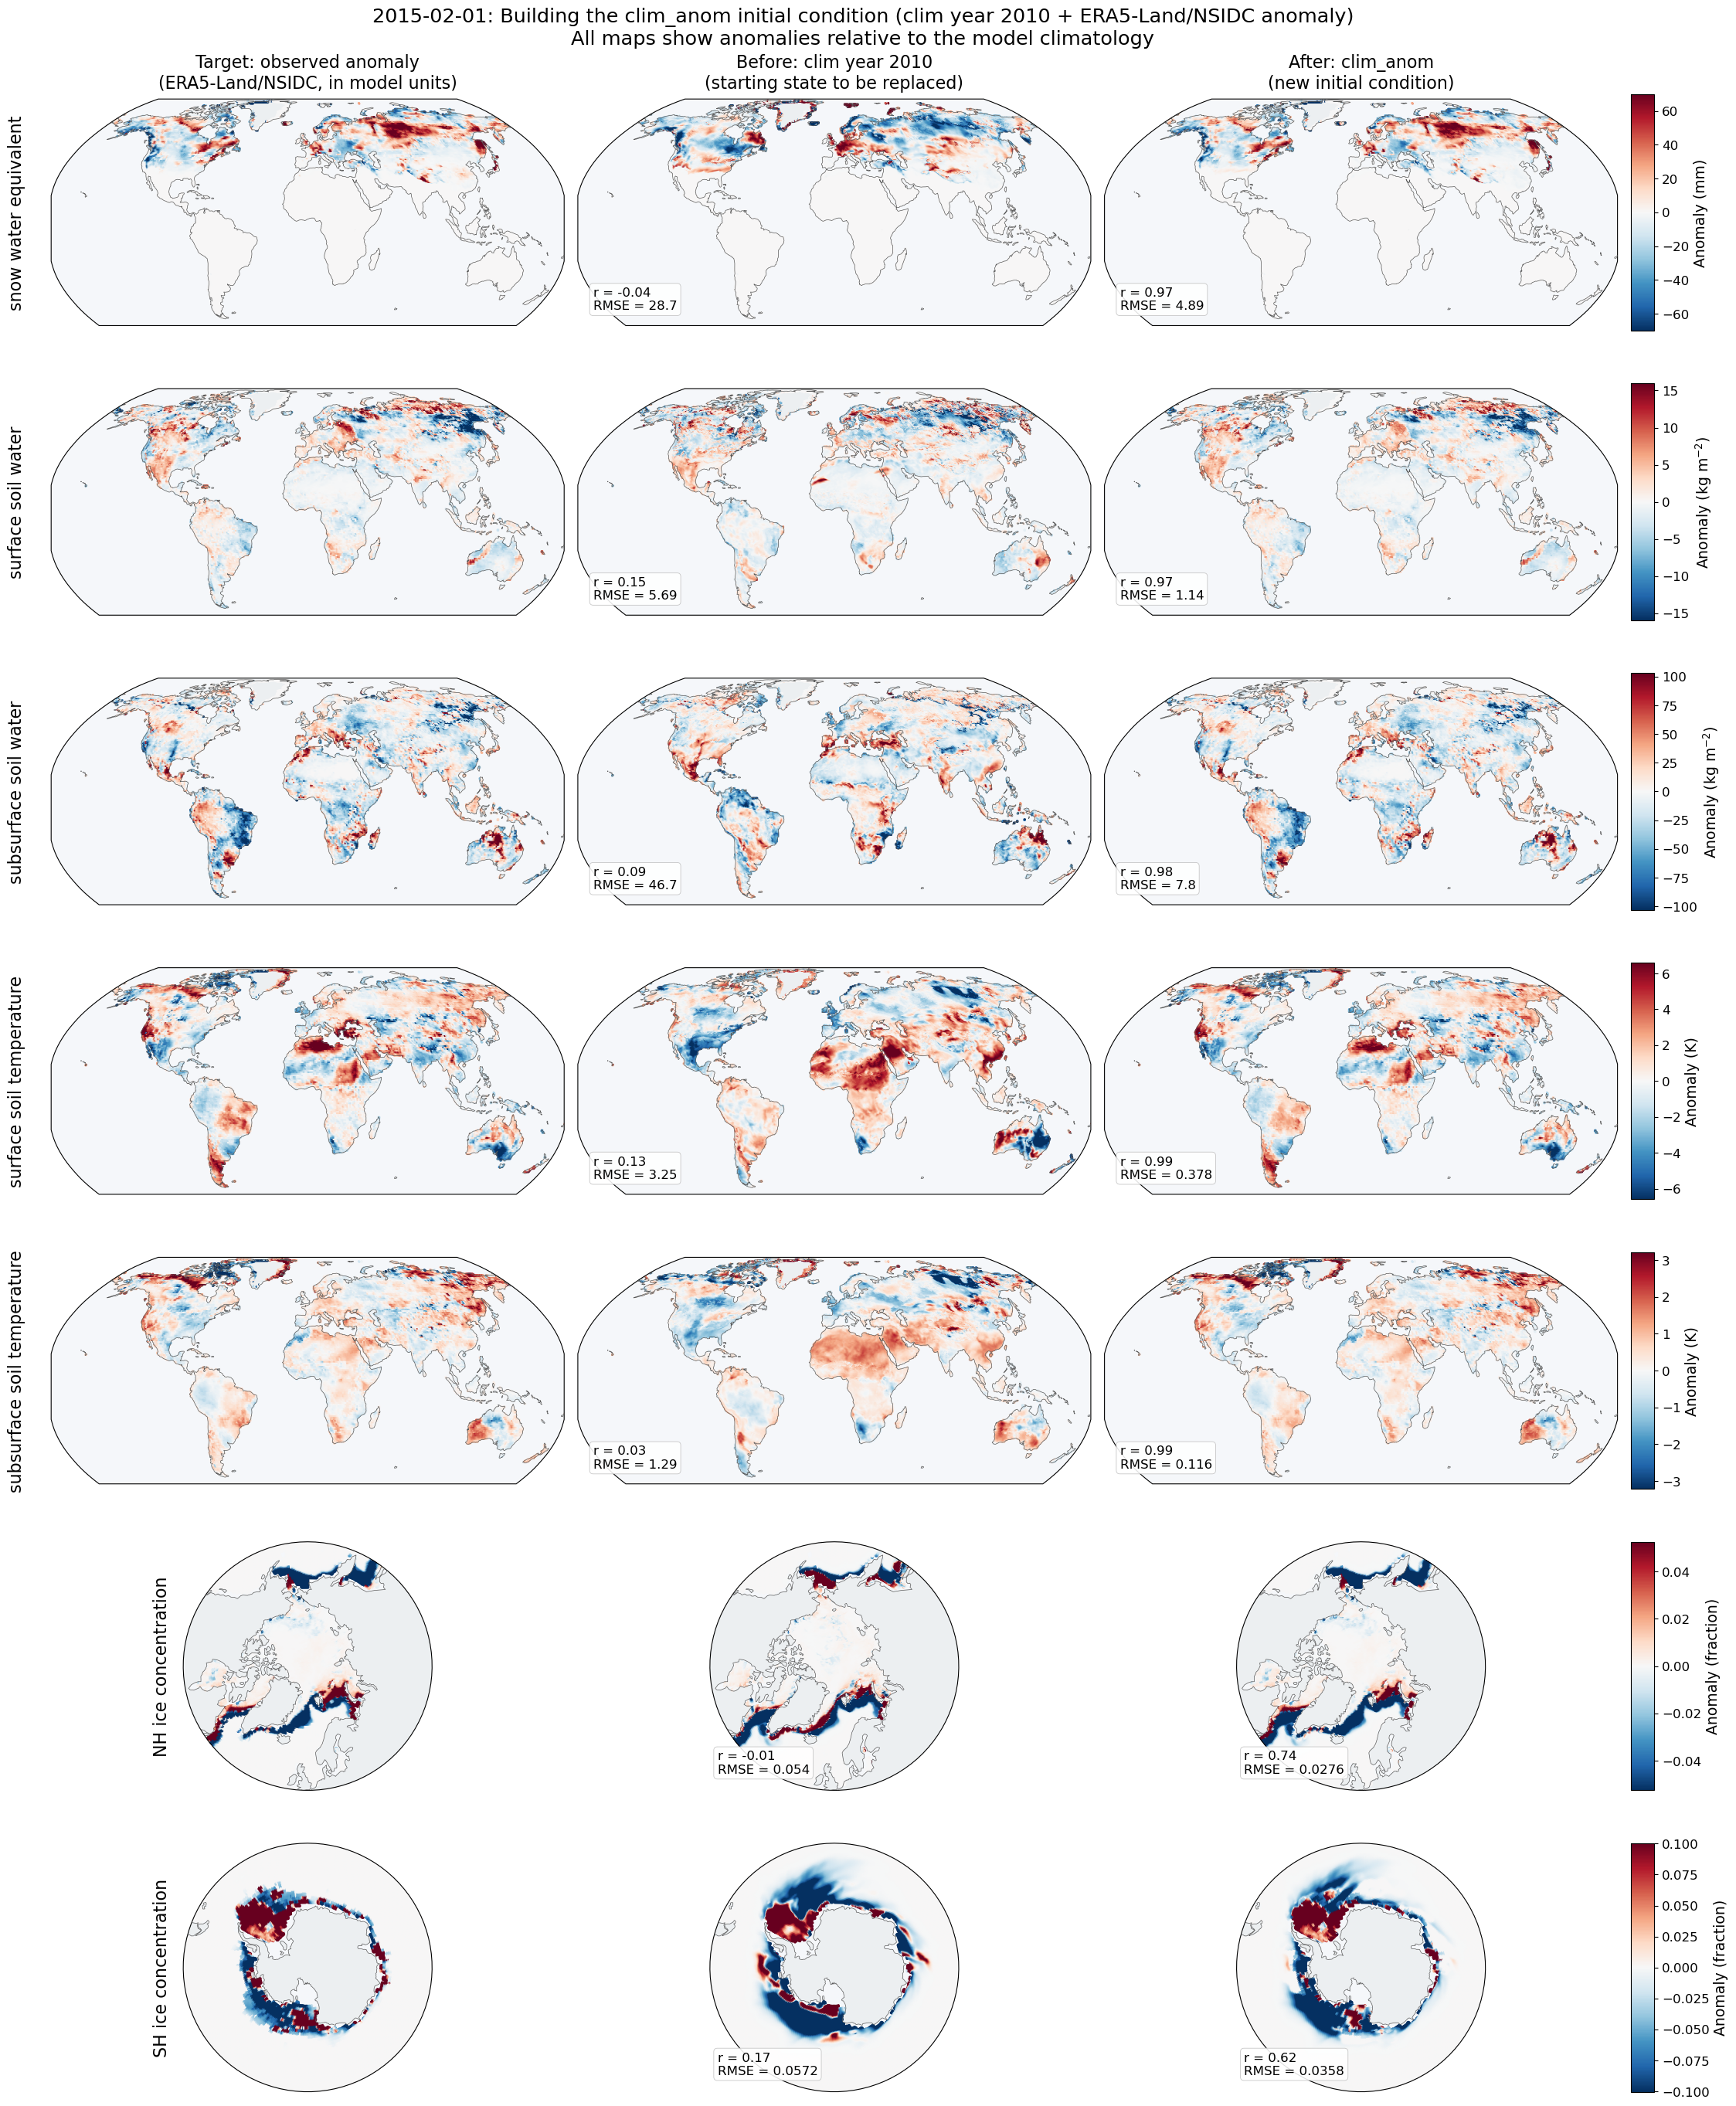

In [6]:
# Anomalies (relative to the model climatology) of the observed target,
# the starting state (before), and the new initial condition (after).
# PCC and RMSE of before and after are calculated against the target.
# Land: global maps; sea ice: polar stereographic maps.

# ---- Figure setup (all adjustable settings) -------------------------------
DATE        = next(iter(plans))  # e.g., "2015-02-01"
FONTSIZE    = 16
PANEL_SIZE  = (6.8, 3.6)
POLAR_LAT   = 50
MARKER      = {"elm": 0.8, "mpassi": 2.5}
PCTL        = 98
CMAP        = "RdBu_r"

LAND_COLOR  = "#eceff1"
OCEAN_COLOR = "#f5f7fa"
COAST_WIDTH = 0.5

UNITS = {
    "snow water equivalent": "mm",
    "surface soil water": "kg m$^{-2}$",
    "subsurface soil water": "kg m$^{-2}$",
    "surface soil temperature": "K",
    "subsurface soil temperature": "K",
    "NH ice concentration": "fraction",
    "SH ice concentration": "fraction",
}

COLUMNS = [
    (
        "target anomaly",
        f"Target: observed anomaly\n({OBS_NAME}, in model units)"
    ),
    (
        "base anomaly",
        "Before: clim year {base}\n(starting state to be replaced)"
    ),
    (
        "realized anomaly",
        "After: clim_anom\n(new initial condition)"
    ),
]

STATS    = True
SAVE_FIG = False
FIG_PATH = Path("clim_anom_increments_{date}.png")
FIG_DPI  = 150
# ---------------------------------------------------------------------------

fs = {
    "title": FONTSIZE,
    "row": FONTSIZE,
    "cbar_label": 0.85 * FONTSIZE,
    "tick": 0.75 * FONTSIZE,
    "suptitle": 1.15 * FONTSIZE,
    "stats": 0.75 * FONTSIZE,
}


def vs_target(m, kind):
    """
    Area-weighted pattern correlation coefficient (PCC)
    and RMSE against the target anomaly.
    """
    ok = (
        m["valid"]
        & np.isfinite(m[kind])
        & np.isfinite(m["target anomaly"])
        & np.isfinite(m["weight"])
        & (m["weight"] > 0)
    )

    if not np.any(ok):
        return np.nan, np.nan

    w = m["weight"][ok]
    w = w / w.sum()

    x = m[kind][ok]
    y = m["target anomaly"][ok]

    dx = x - np.sum(w * x)
    dy = y - np.sum(w * y)

    cov = np.sum(w * dx * dy)
    var_x = np.sum(w * dx**2)
    var_y = np.sum(w * dy**2)

    denom = np.sqrt(var_x * var_y)

    pcc = cov / denom if denom > 0 else np.nan
    rmse = np.sqrt(np.sum(w * (x - y)**2))

    return pcc, rmse


PROJ = {
    "NH": ccrs.NorthPolarStereo(),
    "SH": ccrs.SouthPolarStereo(),
    "global": ccrs.Robinson(),
}

theta = np.linspace(0, 2 * np.pi, 100)

CIRCLE = mpath.Path(
    np.vstack([np.sin(theta), np.cos(theta)]).T * 0.5 + 0.5
)

fields = [
    (c, f)
    for c in increments[DATE]
    for f in increments[DATE][c]
]


def region(comp, name):
    return name[:2] if comp == "mpassi" else "global"


# ---- Figure geometry -------------------------------------------------------

title_h = 3.6 * FONTSIZE / 72 + 0.3

heights = [
    PANEL_SIZE[1] * 1.05
    if region(c, f) != "global"
    else PANEL_SIZE[1]
    for c, f in fields
]

total_h = (
    sum(heights)
    + title_h
    + 1.0 * FONTSIZE / 72
    + 0.6
)

left_w = 1.8 * FONTSIZE / 72 + 0.2
cbar_w = 3.2 * FONTSIZE / 72 + 0.5

total_w = left_w + 3 * PANEL_SIZE[0] + cbar_w

fig = plt.figure(figsize=(total_w, total_h))

grid = fig.add_gridspec(
    len(fields),
    4,
    height_ratios=heights,
    width_ratios=[1, 1, 1, 0.045],
    hspace=0.22,
    wspace=0.035,
    top=1 - (title_h + 1.0 * FONTSIZE / 72) / total_h,
    bottom=0.3 / total_h,
    left=left_w / total_w,
    right=1 - (cbar_w - 0.35) / total_w,
)


# ---- Plot each variable ----------------------------------------------------

for r, (comp, name) in enumerate(fields):

    m = increments[DATE][comp][name]["maps"]

    ok = (
        m["valid"]
        & np.isfinite(m["target anomaly"])
    )

    reg = region(comp, name)

    abs_target = np.abs(m["target anomaly"][ok])

    if abs_target.size and np.isfinite(abs_target).any():
        vmax = np.nanpercentile(abs_target, PCTL)
        if not np.isfinite(vmax) or vmax <= 0:
            vmax = 1.0
    else:
        vmax = 1.0

    for c, (kind, title) in enumerate(COLUMNS):

        ax = fig.add_subplot(
            grid[r, c],
            projection=PROJ[reg]
        )

        ax.set_facecolor(OCEAN_COLOR)

        valid = ok & np.isfinite(m[kind])

        if reg == "global":

            ax.set_global()

            ax.add_feature(
                cfeature.LAND,
                facecolor=LAND_COLOR,
                zorder=0
            )

        else:

            lat0, lat1 = (
                (POLAR_LAT, 90)
                if reg == "NH"
                else (-90, -POLAR_LAT)
            )

            ax.set_extent(
                [-180, 180, lat0, lat1],
                crs=ccrs.PlateCarree()
            )

            ax.set_boundary(
                CIRCLE,
                transform=ax.transAxes
            )

            ax.add_feature(
                cfeature.LAND,
                facecolor=LAND_COLOR,
                zorder=1
            )

        sc = ax.scatter(
            m["lon"][valid],
            m["lat"][valid],
            c=m[kind][valid],
            s=MARKER[comp],
            cmap=CMAP,
            vmin=-vmax,
            vmax=vmax,
            transform=ccrs.PlateCarree(),
            rasterized=True,
            zorder=2
        )

        ax.coastlines(
            linewidth=COAST_WIDTH,
            color="0.35",
            zorder=3
        )

        # ---- Column titles ------------------------------------------------

        if r == 0:

            head = title.format(
                base=base_years[DATE][comp]
            )

            ax.set_title(
                head,
                fontsize=fs["title"],
                pad=10
            )

        # ---- PCC / RMSE ---------------------------------------------------

        if STATS and kind != "target anomaly":

            pcc, rmse = vs_target(m, kind)

            badge = (
                f"r = {pcc:.2f}\n"
                f"RMSE = {rmse:.3g}"
            )

            badge_x = 0.26 if reg != "global" else 0.04
            badge_y = 0.08

            ax.text(
                badge_x,
                badge_y,
                badge,
                transform=ax.transAxes,
                fontsize=fs["stats"],
                verticalalignment="bottom",
                horizontalalignment="left",
                bbox=dict(
                    boxstyle="round,pad=0.28",
                    facecolor="white",
                    alpha=0.88,
                    edgecolor="0.75",
                    linewidth=0.6
                ),
                zorder=5
            )

        # ---- Row labels --------------------------------------------------

        if c == 0:

            label_x = 0.18 if reg != "global" else -0.05

            ax.text(
                label_x,
                0.5,
                name,
                transform=ax.transAxes,
                rotation=90,
                ha="right",
                va="center",
                fontsize=fs["row"],
                fontweight="medium"
            )

    # ---- Colorbar for each variable --------------------------------------

    cb = fig.colorbar(
        sc,
        cax=fig.add_subplot(grid[r, 3])
    )

    cb.set_label(
        f"Anomaly ({UNITS.get(name, '')})",
        fontsize=fs["cbar_label"]
    )

    cb.ax.tick_params(
        labelsize=fs["tick"]
    )


# ---- Main figure title -----------------------------------------------------

fig.suptitle(
    f"{DATE}: Building the clim_anom initial condition "
    f"(clim year {base_years[DATE]['elm']} + {OBS_NAME} anomaly)\n"
    "All maps show anomalies relative to the model climatology",
    fontsize=fs["suptitle"],
    y=1 - 0.2 / total_h,
    va="top"
)


# ---- Save / display --------------------------------------------------------

if SAVE_FIG:

    output_path = Path(
        str(FIG_PATH).format(
            date=DATE.replace("-", "")
        )
    )

    fig.savefig(
        output_path,
        dpi=FIG_DPI,
        bbox_inches="tight"
    )

plt.show()

## 3. Evaluation

Field distances $d_f$ (as in `02`) of the base (`clim`) year, the `obs` year, and the new
`clim_anom` state, computed from the key fields of the new state (the files need not be written).

- **vs observations**: target is the observed standardized anomaly on the target date (the `obs` metric), at the
  `BOX` scale and at model points.
- **vs actual 2015** (2015 dates only): target is the actual 2015 BruteForce state (the closeness
  test of `04`).

In [ ]:
def year_state(plan, year):
    """Key fields of a candidate year from the cache."""
    i = plan.candidate_years.index(year)
    return {c: {f: v[0][i] for f, v in load_key_fields(plan, c, CACHE_DIR, log=quiet).items()}
            for c in increments[plan.target_date]}


def anom_state(plan):
    state = year_state(plan, base_years[plan.target_date]["elm"])
    for comp, fields in increments[plan.target_date].items():
        base = year_state(plan, base_years[plan.target_date][comp])[comp]
        state[comp] = {**base, **{f: inc["new"] for f, inc in fields.items()}}
    return state


evaluation = []
for date, plan in plans.items():
    states = {"clim year": year_state(plan, base_years[date]["elm"]),
              "obs year": year_state(plan, obs_years[date]["elm"]),
              LABEL: anom_state(plan)}
    targets = [(OBS_NAME, "obs", BOX), (OBS_NAME, "obs", None)]
    if int(date[:4]) not in plan.candidate_years and int(date[:4]) <= 2018:
        targets += [("actual 2015", int(date[:4]), BOX), ("actual 2015", int(date[:4]), None)]
    for tname, target, box in targets:
        table = state_distance(plan, states, target=target, box=box, cache_dir=CACHE_DIR, log=quiet)
        evaluation.append(table.assign(target_date=date, versus=tname,
                                       scale=f"{box[0]}x{box[1]}" if box else "points"))
evaluation = pd.concat(evaluation).rename_axis("state").reset_index()
evaluation = evaluation.set_index(["versus", "scale", "target_date", "state"]).sort_index()
display(evaluation[["elm", "mpassi", "joint"]].unstack("state").round(3))

In [ ]:
# Joint distance by date: lower is closer to the target.
# ---- Figure setup (all adjustable settings) --------------------------------------------
FONTSIZE   = 18                  # base font size: panel titles and axis labels; other text scales from it
PANEL_SIZE = (6.5, 5.0)          # width, height of one panel (inches)
STATES     = ["clim year", "obs year", LABEL]          # bars, in this order
COLORS     = ["0.6", "tab:blue", "tab:red"]
BAR_WIDTH  = 0.8
YLIM       = None                # e.g. (0, 1.8); None for automatic
SAVE_FIG   = False               # True saves the figure as FIG_PATH
FIG_PATH   = Path("clim_anom_joint_distance.png")
FIG_DPI    = 150
# -----------------------------------------------------------------------------------------
fs = {"title": FONTSIZE, "label": FONTSIZE, "tick": 0.8 * FONTSIZE, "legend": 0.8 * FONTSIZE}
groups = evaluation["joint"].unstack("state").groupby(level=["versus", "scale"])
fig, axes = plt.subplots(1, len(groups), figsize=(PANEL_SIZE[0] * len(groups), PANEL_SIZE[1]),
                         sharey=True, squeeze=False)
for ax, ((versus, scale), table) in zip(axes[0], groups):
    table = table.droplevel(["versus", "scale"])[STATES]
    table.plot.bar(ax=ax, rot=45, width=BAR_WIDTH, color=COLORS, legend=False)
    ax.axhline(1, color="k", lw=0.8)
    ax.set_title(f"vs {versus}\n({scale})", fontsize=fs["title"])
    ax.set_xlabel("")
    ax.tick_params(labelsize=fs["tick"])
    if YLIM is not None:
        ax.set_ylim(*YLIM)
axes[0, 0].set_ylabel("joint distance D (lower is closer)", fontsize=fs["label"])
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, fontsize=fs["legend"], loc="lower center", ncol=len(STATES), frameon=False)
fig.tight_layout(rect=(0, 0.1, 1, 1))
if SAVE_FIG:
    fig.savefig(FIG_PATH, dpi=FIG_DPI, bbox_inches="tight")
plt.show()

In [ ]:
# Field distances averaged over dates.
display(evaluation.drop(columns=["elm", "mpassi", "joint"]).groupby(level=["versus", "scale", "state"]).mean()
        .T.round(3))

## 4. Write the `clim_anom` restarts

Copies each base restart to `OUT_ROOT/YYYYMMDD/clim_anom/`, applies the increments there (the
source archive is only read), copies the river restart from the base land year, writes
`rpointer.lnd`, `rpointer.rof`, `rpointer.ice`, and records the plan, base years, settings, and the
increment statistics in `anomaly.json`. The new files are then re-read to check that their key
fields equal the computed ones. Set `WRITE_OUTPUT = True` to run.

In [ ]:
if WRITE_OUTPUT:
    for date, plan in plans.items():
        write_anomaly_restarts(plan, base_years[date], increments[date],
                               stats.loc[date].reset_index(), SETTINGS, overwrite=OVERWRITE)

rows = []
for date, plan in plans.items():
    for comp in COMPONENTS:
        out = plan.output(comp)
        row = {"target_date": date, "component": comp, "base year": base_years[date][comp],
               "written": out.is_file()}
        if out.is_file() and comp in increments[date]:
            written = read_key_fields(comp, out)
            err = 0.0
            for name, inc in increments[date][comp].items():
                values, weight = written[name]
                ok = (weight > 0) & np.isfinite(values) & np.isfinite(inc["new"])
                err = max(err, float(np.max(np.abs(values[ok] - inc["new"][ok])
                                            / (np.abs(inc["new"][ok]).max() or 1.0))))
            row["max rel. key-field error"] = err
        rows.append(row)
display(pd.DataFrame(rows))

## 5. Soil moisture and soil temperature profiles

Region-mean vertical profiles for one date, to check that the adjusted soil profiles stay continuous and
move toward the observations:

- **Model climatology** (grey): mean over the candidate years.
- **Model before** (blue, dashed): the `clim` year used as the base.
- **Model after** (red): the new `clim_anom` initial condition.
- **Observation** (black bars): ERA5-Land at its four soil levels (0-7, 7-28, 28-100, 100-289 cm); each bar
  spans the level's depth range.

Soil moisture is volumetric water content (m3/m3; model liquid + ice divided by layer thickness), soil
temperature is in K. The top row shows absolute values (model and observation climatologies differ); the
bottom rows show anomalies from each source's own 1995-2018 climatology, which is what the adjustment uses.
Model layers below 3.8 m hold no water and are not shown.

The adjustment transfers the observed *standardized* anomaly, scaled by the model's own interannual
variability, so the model anomaly after the adjustment should match the observation in sign and vertical shape,
while its magnitude follows the model's variability (soil-moisture variability differs most between ERA5-Land
and E3SM). Region means also mix columns with different anomalies.

In [ ]:
# Region-mean soil moisture and temperature profiles: observation, model before and after the adjustment.
# ---- Figure setup (all adjustable settings) --------------------------------------------
DATE        = next(iter(plans))  # date to plot, e.g. "2015-02-01"
REGIONS     = {                  # name: (lat0, lat1, lon0, lon1), lon in degrees east
    "Northern Eurasia": (50, 70, 30, 140),
    "North America": (30, 55, -125, -70),
    "Amazon": (-15, 5, -75, -45),
    "Sahel": (5, 20, -15, 40),
    "Australia": (-35, -15, 115, 150),
}
FONTSIZE    = 18                 # base font size: panel titles and axis labels; other text scales from it
PANEL_SIZE  = (4.6, 5.2)         # width, height of one panel (inches)
MAX_DEPTH   = 3.8                # deepest depth shown (m)
LOG_DEPTH   = True               # log depth axis (resolves the thin top layers)
COLORS      = {"clim": "0.55", "base": "tab:blue", "new": "tab:red", "obs": "k"}
LINE_WIDTH  = 2.5
SAVE_FIG    = False              # True saves the figure as FIG_PATH
FIG_PATH    = Path("clim_anom_soil_profiles_{date}.png")
FIG_DPI     = 150
# -----------------------------------------------------------------------------------------
plan = plans[DATE]
prof = anom_restart.soil_profiles(plan, base_years[DATE]["elm"], plan.output("elm"), REGIONS, log=quiet)
fs = {"title": FONTSIZE, "label": FONTSIZE, "tick": 0.8 * FONTSIZE, "legend": 0.8 * FONTSIZE,
      "suptitle": 1.1 * FONTSIZE}
z, zi = prof["depth"], prof["interfaces"]
levels = list(prof["obs_levels"].values())
rows = [("theta", "abs", "soil moisture (m$^3$ m$^{-3}$)"), ("theta", "anom", "soil moisture anomaly (m$^3$ m$^{-3}$)"),
        ("tsoi", "abs", "soil temperature (K)"), ("tsoi", "anom", "soil temperature anomaly (K)")]
fig, axes = plt.subplots(len(rows), len(prof["regions"]),
                         figsize=(PANEL_SIZE[0] * len(prof["regions"]), PANEL_SIZE[1] * len(rows)),
                         sharey=True, squeeze=False)
for r, (key, kind, label) in enumerate(rows):
    for c, region in enumerate(prof["regions"]):
        ax = axes[r, c]
        mclim, oclim = prof["model"]["clim"][key][c], prof["obs"]["clim"][key][c]
        ref_m, ref_o = (mclim, oclim) if kind == "anom" else (0.0, 0.0)
        if kind == "abs":
            ax.plot(mclim, z, "-", color=COLORS["clim"], lw=LINE_WIDTH, label="model climatology")
        else:
            ax.axvline(0, color=COLORS["clim"], lw=1)
        ax.plot(prof["model"]["base"][key][c] - ref_m, z, "--o", color=COLORS["base"], lw=LINE_WIDTH, ms=4,
                label=f"model before (clim year {base_years[DATE]['elm']})")
        ax.plot(prof["model"]["new"][key][c] - ref_m, z, "-o", color=COLORS["new"], lw=LINE_WIDTH, ms=4,
                label="model after (clim_anom)")
        obs = prof["obs"]["target"][key][c] - ref_o
        for (top, bot), v in zip(levels, obs):
            ax.plot([v, v], [max(top, 0.005), bot], color=COLORS["obs"], lw=LINE_WIDTH + 1.5,
                    solid_capstyle="butt")
        ax.plot([], [], color=COLORS["obs"], lw=LINE_WIDTH + 1.5, label=f"observation ({OBS_NAME.split('/')[0]})")
        if LOG_DEPTH:
            ax.set_yscale("log")
        ax.set_ylim(MAX_DEPTH, 0.005 if LOG_DEPTH else 0)
        ax.tick_params(labelsize=fs["tick"])
        ax.grid(alpha=0.3)
        if r == 0:
            ax.set_title(region, fontsize=fs["title"])
        if c == 0:
            ax.set_ylabel("depth (m)", fontsize=fs["label"])
        ax.set_xlabel(label, fontsize=0.85 * fs["label"])
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, fontsize=fs["legend"], loc="lower center", ncol=len(labels), frameon=False)
fig.suptitle(f"{DATE}: region-mean soil profiles, observation and model before / after adding the observed anomaly",
             fontsize=fs["suptitle"])
fig.tight_layout(rect=(0, 0.035, 1, 0.97))
if SAVE_FIG:
    fig.savefig(str(FIG_PATH).format(date=DATE.replace("-", "")), dpi=FIG_DPI, bbox_inches="tight")
plt.show()

## 6. Key findings

**Table. Joint distance D of the three initial-condition options from two references** (lower is closer;
D on 15°x30° box means, observable fields). *vs observed*: the observed (ERA5-Land/NSIDC) anomaly on the target
date; a typical candidate year has D of about 1.4-1.5. *vs actual 2015*: the actual 2015 BruteForce state
(2015 dates only). Each cell gives clim year / obs year / **clim_anom**.

| Date | vs observed | vs actual 2015 |
|---|---|---|
| 2015-02-01 | 1.24 / 1.13 / **0.63** | 1.35 / 1.17 / **0.97** |
| 2015-05-01 | 1.22 / 1.11 / **0.69** | 1.26 / 0.98 / **0.93** |
| 2015-08-01 | 1.22 / 1.22 / **0.53** | 1.16 / 1.15 / **0.81** |
| 2015-11-01 | 1.45 / 1.16 / **0.71** | 1.55 / 1.20 / **0.99** |
| 2026-02-01 | 1.22 / 1.22 / **0.66** | -- |
| 2026-05-01 | 1.39 / 1.19 / **0.56** | -- |
| 2026-08-01 | 1.42 / 1.40 / **0.58** | -- |

1. **The increments reproduce the observed anomaly well over land and less well for sea ice.** The realized
   anomaly correlates with the target at 0.95-0.99 for soil water and soil temperature and 0.77-0.97 for snow,
   but 0.74-0.95 for NH and only 0.30-0.62 for SH ice concentration. Ice and snow cannot be created where the
   base year has none (1-6% of the area), and the SH ice edge differs most between years.
2. **`clim_anom` is the closest state to the observed anomaly on every date** (D = 0.53-0.71, against 1.11-1.40
   for the obs year and 1.22-1.45 for the clim year; at model points 0.70-0.83 against 1.27-1.46). This is
   expected, since it is built from that anomaly.
3. **`clim_anom` is also the closest state to the actual 2015 restarts on all four 2015 dates** (D = 0.81-0.99,
   against 0.98-1.20 for the obs year and 1.16-1.55 for the clim year), at both box scale and model points
   (1.10-1.16 against 1.16-1.30 and 1.33-1.52). This is an independent check: 2015 was not used to build it.
4. **The gain comes mainly from soil temperature, soil water, and NH sea ice** (mean d_f vs actual 2015 at box
   scale: soil temperature 0.52 vs 1.19 for the obs year, surface soil water 0.93 vs 1.33, NH ice
   concentration 0.79 vs 1.06). For snow (0.87 vs 0.78) and SH ice concentration (1.14 vs 1.10) the obs year
   is as close or closer.
5. **The written restarts carry exactly the computed fields** (key-field error < 1e-7). Their stability in the
   model has not been tested yet; a short run is needed before use (soil phase partition, water table, and
   sea-ice thickness are not adjusted).
